# **COMPUTER VISION**

> Assignment 02: All the codes and questions of the given tasks are present in this file


Submitted by:

1.   Syed Furqan Ali (451802)
2.   Rabbia Waheed (494532)




# **TASKS**







>  **Problem 1: Grayscale Conversion**




In [ ]:
!pip install opencv-python

In [ ]:
def rgb_to_gray(r, g, b):
    gray = 0.299 * r + 0.587 * g + 0.114 * b
    return round(gray)

# provided colours
color1 = (120, 200, 150)
color2 = (50, 100, 200)

gray1 = rgb_to_gray(color1[0], color1[1], color1[2])
gray2 = rgb_to_gray(color2[0], color2[1], color2[2])

print(f"RGB{color1} converts to grayscale: {gray1}")
print(f"RGB{color2} converts to grayscale: {gray2}")

RGB(120, 200, 150) converts to grayscale: 170
RGB(50, 100, 200) converts to grayscale: 96


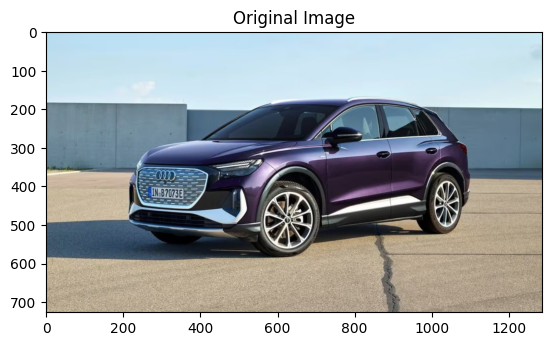

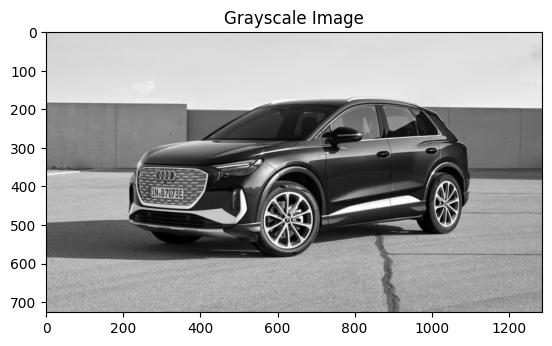

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load and convert to grayscale
image = cv2.imread("/content/rgb_car.jpg")
original_colured_image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)# Convert BGR to RGB for matplotlib

# Check if image loading was successful
if image is None:
    print("Error: Could not load image. Please check the file path and ensure the image is not corrupted.")
else:
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    # Display grayscale image
    plt.imshow(original_colured_image)
    plt.title("Original Image")
    plt.show()
    plt.imshow(gray, cmap='gray')
    plt.title("Grayscale Image")
    plt.show()

**Questions:**


1.   Why do we use different weights for the RGB channels in grayscale conversion?\
We use different weights for RGB channels in grayscale conversion because human eyes perceive colors differently. The standard weights (e.g., 0.299 for R, 0.587 for G, 0.114 for B) reflect our greater sensitivity to green light and lesser to blue. This mimics how our vision processes luminance, ensuring the grayscale image looks natural. Equal weights would distort brightness perception, making the result less accurate.
2.   How does the human eye's sensitivity to different colors affect the grayscale image?\
The human eye is most sensitive to green light, less to red, and least to blue, influencing grayscale conversion. By weighting RGB channels (e.g., 0.587 for G, 0.299 for R, 0.114 for B), the grayscale image aligns with our perception of brightness. Higher green sensitivity means it contributes more to luminance, while blue’s lower impact reduces its influence. This ensures the grayscale output reflects how we naturally see contrast and intensity. Uneven sensitivity ignored would skew the image’s perceived brightness.





>  **Problem 2: Linear Convolution**



In [ ]:
import numpy as np

# Define the image matrix I
I = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
])

# Define the mean filter kernel K
K = (1/9) * np.array([
    [1, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
])

# Initialize the filtered image with zeros
filtered_image = np.zeros_like(I, dtype=float)

# Pad the input image I with zeros to handle the borders
# The padding ensures that the convolution operation can be applied to all pixels
padded_image = np.pad(I, pad_width=1, mode='constant', constant_values=0)

# Iterate through each pixel of the original image (excluding padding)
for i in range(1, padded_image.shape[0] - 1):
    for j in range(1, padded_image.shape[1] - 1):
        # Extract the 3x3 neighborhood around the current pixel
        # i-1:i+2 selects rows from i-1 to i+1
        # j-1:j+2 selects columns from j-1 to j+1
        region = padded_image[i-1:i+2, j-1:j+2]

        # Apply the mean filter by performing element-wise multiplication
        # between the region and the kernel, then sum the result
        filtered_image[i-1, j-1] = np.sum(region * K)

# Print the filtered image
print(filtered_image)


[[13.33333333 23.33333333 17.77777778]
 [30.         50.         36.66666667]
 [26.66666667 43.33333333 31.11111111]]


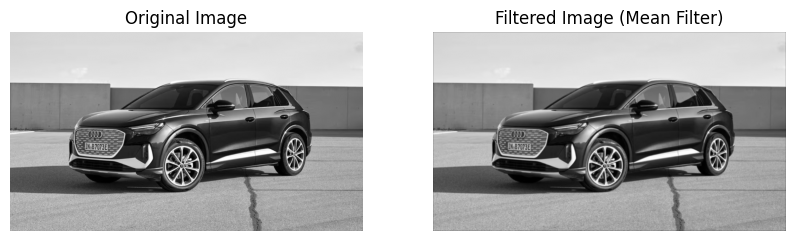

In [ ]:
from PIL import Image
import numpy as np
from scipy.ndimage import convolve
import matplotlib.pyplot as plt

# Load the image using Pillow
image_path = "/content/rgb_car.jpg"
image = Image.open(image_path).convert('L')  # Convert to grayscale

# Convert the image to a NumPy array
image_array = np.array(image, dtype=np.float64)

# Define the mean filter kernel (3x3)
mean_kernel = np.ones((3, 3)) / 9

# Apply the mean filter using convolution
filtered_image = convolve(image_array, mean_kernel, mode='constant', cval=0.0)

# Convert the filtered image back to an 8-bit image
filtered_image = np.uint8(filtered_image)

# Display the original and filtered images
plt.figure(figsize=(10, 5))

# Original image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image_array, cmap='gray')
plt.axis('off')

# Filtered image
plt.subplot(1, 2, 2)
plt.title("Filtered Image (Mean Filter)")
plt.imshow(filtered_image, cmap='gray')
plt.axis('off')

plt.show()



> **Problem 3:Gaussian Filtering**



In [ ]:
import numpy as np

# Define the image matrix I (the input image)
I = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
])

# Define the Gaussian kernel K (normalized by dividing each element by 16)
K = (1/16) * np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
])

# Initialize an empty matrix to store the filtered image
# The size of filtered_image matches the original image
filtered_image = np.zeros_like(I, dtype=float)

# Pad the image with zeros on all sides to handle edge cases during convolution
# Padding ensures that we can apply the kernel to pixels at the edges
padded_image = np.pad(I, pad_width=1, mode='constant', constant_values=0)

# Loop through each pixel in the original image
# The padded_image is used to extract neighborhoods for convolution
for i in range(1, padded_image.shape[0] - 1):  # Iterate over rows (excluding padding)
    for j in range(1, padded_image.shape[1] - 1):  # Iterate over columns (excluding padding)
        # Extract a 3x3 region (neighborhood) centered at the current pixel
        region = padded_image[i-1:i+2, j-1:j+2]

        # Perform element-wise multiplication between the region and kernel
        # Then sum up all values to get the new pixel value
        filtered_image[i-1, j-1] = np.sum(region * K)

# Print the resulting filtered image
print("Filtered Image:")
print(filtered_image)


Filtered Image:
[[13.125 22.5   20.625]
 [32.5   50.    42.5  ]
 [35.625 52.5   43.125]]


**Questions:**

1.   How does the mean filter affect the image compared to the Gaussian filter?\
A mean filter, or average filter, blurs an image by replacing each pixel with the average value of its neighbors, reducing noise but often losing sharp details uniformly. It applies equal weight to all pixels in the kernel, which can make edges look overly soft. In contrast, a Gaussian filter also blurs to reduce noise but uses a weighted average based on a Gaussian distribution, giving more influence to closer pixels. This preserves edges better and produces a smoother, more natural result, though it’s computationally heavier than the mean filter.
2.   Why is Gaussian filtering preferred for edge preservation?\
Gaussian filtering is preferred because it weights nearby pixels more heavily, which smooths noise while minimizing blurring at edges. Its continuous, bell-shaped kernel preserves the natural structure of edges by reducing the influence of distant pixels. This balance of noise reduction and edge retention makes Gaussian filtering ideal for image preprocessing.

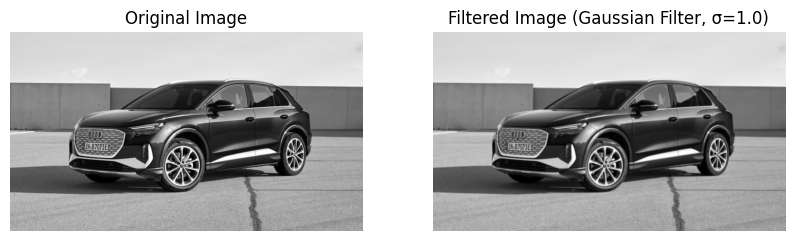

In [ ]:
from PIL import Image
import numpy as np
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt

# Load the image using Pillow
image_path = "/content/rgb_car.jpg"
image = Image.open(image_path).convert('L')  # Convert to grayscale

# Convert the image to a NumPy array
image_array = np.array(image, dtype=np.float64)

# Apply Gaussian filtering
sigma = 1.0  # Standard deviation of the Gaussian kernel (controls the amount of blur)
filtered_image = gaussian_filter(image_array, sigma=sigma)

# Convert the filtered image back to an 8-bit image
filtered_image = np.uint8(filtered_image)

# Display the original and filtered images
plt.figure(figsize=(10, 5))

# Original image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image_array, cmap='gray')
plt.axis('off')

# Filtered image
plt.subplot(1, 2, 2)
plt.title(f"Filtered Image (Gaussian Filter, σ={sigma})")
plt.imshow(filtered_image, cmap='gray')
plt.axis('off')

plt.show()



> **Problem 4:Convolution**



In [ ]:
import numpy as np

# Define the image matrix I
I = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
])

# Define the convolution kernel K
K = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

# Initialize the filtered image with zeros
filtered_image = np.zeros_like(I, dtype=float)

# Pad the input image I with zeros to handle the borders
padded_image = np.pad(I, pad_width=1, mode='constant', constant_values=0)

# Iterate through each pixel of the original image (excluding padding)
for i in range(1, padded_image.shape[0] - 1):
    for j in range(1, padded_image.shape[1] - 1):
        # Extract the 3x3 neighborhood around the current pixel
        region = padded_image[i-1:i+2, j-1:j+2]

        # Apply the convolution by performing element-wise multiplication
        # between the region and the kernel, then sum the result
        filtered_image[i-1, j-1] = np.sum(region * K)

# Print the filtered image
print(filtered_image)

[[ -70.  -40.   70.]
 [-150.  -60.  150.]
 [-130.  -40.  130.]]


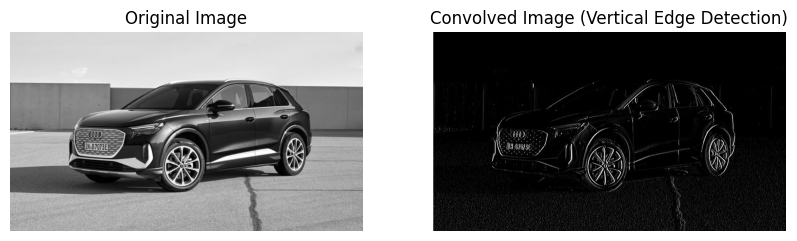

In [ ]:
from PIL import Image
import numpy as np
from scipy.ndimage import convolve
import matplotlib.pyplot as plt

# Load the image using Pillow
image_path = "/content/rgb_car.jpg"  # Replace with the path to your image
image = Image.open(image_path).convert('L')  # Convert to grayscale

# Convert the image to a NumPy array
image_array = np.array(image, dtype=np.float64)

# Define the convolution kernel K
K = np.array([
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1]
])

# Perform convolution
convolved_image = convolve(image_array, K, mode='constant', cval=0.0)

# Normalize the convolved image to the range [0, 255]
convolved_image = np.clip(convolved_image, 0, 255).astype(np.uint8)

# Display the original and convolved images
plt.figure(figsize=(10, 5))

# Original image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image_array, cmap='gray')
plt.axis('off')

# Convolved image
plt.subplot(1, 2, 2)
plt.title("Convolved Image (Vertical Edge Detection)")
plt.imshow(convolved_image, cmap='gray')
plt.axis('off')

plt.show()


**Questions:**

1.   What is the effect of convolution on the image?\
Convolution applies a filter to an image by computing a weighted sum of pixel values in a local neighborhood. This process alters image features enhancing edges, smoothing noise, or sharpening details depending on the kernel used. It essentially transforms the image by highlighting or suppressing specific patterns, making it a key tool in image processing and computer vision.
2.   How does the choice of kernel affect the result of convolution?\
The kernel's design directly influences which image features are emphasized or suppressed. For example, a smoothing kernel (like a Gaussian) averages pixel values to reduce noise, while an edge detection kernel (such as Sobel or Laplacian) highlights intensity changes to accentuate boundaries. The size, shape, and weight distribution within the kernel determine the scale and nature of the filtering effect, impacting how detailed or abstract the resulting image appears.

# **CANNY EDGE DETECTION**

*   Problem 5: Gradient Calculation
*   Problem 6: Gradient Magnitude and Direction
*   Problem 7: Non-Maximum Suppression
*   Problem 8: Double Thresholding  
*   Problem 9: Hyteresis Thresholding



In [ ]:
import numpy as np
from scipy import signal, ndimage
from skimage import feature

def canny_edge_detection(image):
    """
    Implement Canny Edge Detection algorithm

    Steps:
    1. Gradient Calculation (Gx and Gy) using Sobel operators
    2. Compute Gradient Magnitude and Direction
    3. Non-Maximum Suppression
    4. Double Thresholding
    5. Hysteresis Thresholding
    """
    # Input Image
    I = np.array([
        [10, 20, 30],
        [40, 50, 60],
        [70, 80, 90]
    ], dtype=np.float64)

    # Sobel Kernels for X and Y gradients
    kernel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64)
    kernel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float64)

    # Step 1: Calculate X and Y Gradients
    Gx = signal.convolve2d(I, kernel_x, mode='same', boundary='symm')
    Gy = signal.convolve2d(I, kernel_y, mode='same', boundary='symm')

    # Step 2: Gradient Magnitude and Direction
    gradient_magnitude = np.sqrt(Gx**2 + Gy**2)
    gradient_direction = np.arctan2(Gy, Gx) * 180 / np.pi

    # Step 3: Non-Maximum Suppression
    image_maxima = feature.peak_local_max(
        gradient_magnitude,
        footprint=np.ones((3, 3)),
        exclude_border=False,
        num_peaks=9
    )
    suppressed = np.zeros_like(gradient_magnitude)
    suppressed[tuple(image_maxima.T)] = gradient_magnitude[tuple(image_maxima.T)]

    # Step 4: Double Thresholding
    high_threshold = 100
    low_threshold = 50

    strong_edges = (suppressed >= high_threshold)
    weak_edges = ((suppressed >= low_threshold) & (suppressed < high_threshold))

    # Step 5: Hysteresis Thresholding
    edges = strong_edges.copy()
    for i in range(I.shape[0]):
        for j in range(I.shape[1]):
            if weak_edges[i, j]:
                # Check if any of its neighbours are strong edges
                if np.any(strong_edges[max(0, i-1):min(I.shape[0], i+2),
                                       max(0, j-1):min(I.shape[1], j+2)]):
                    edges[i, j] = True

    return {
        'original_image': I,
        'x_gradient': Gx,
        'y_gradient': Gy,
        'gradient_magnitude': gradient_magnitude,
        'gradient_direction': gradient_direction,
        'suppressed': suppressed,
        'strong_edges': strong_edges,
        'weak_edges': weak_edges,
        'final_edges': edges
    }

# Run the Canny Edge Detection
results = canny_edge_detection(None)

# Print results
for key, value in results.items():
    print(f"{key}:\n", value, "\n")

original_image:
 [[10. 20. 30.]
 [40. 50. 60.]
 [70. 80. 90.]] 

x_gradient:
 [[-40. -80. -40.]
 [-40. -80. -40.]
 [-40. -80. -40.]] 

y_gradient:
 [[-120. -120. -120.]
 [-240. -240. -240.]
 [-120. -120. -120.]] 

gradient_magnitude:
 [[126.49110641 144.22205102 126.49110641]
 [243.31050121 252.98221281 243.31050121]
 [126.49110641 144.22205102 126.49110641]] 

gradient_direction:
 [[-108.43494882 -123.69006753 -108.43494882]
 [ -99.46232221 -108.43494882  -99.46232221]
 [-108.43494882 -123.69006753 -108.43494882]] 

suppressed:
 [[  0.           0.           0.        ]
 [  0.         252.98221281   0.        ]
 [  0.           0.           0.        ]] 

strong_edges:
 [[False False False]
 [False  True False]
 [False False False]] 

weak_edges:
 [[False False False]
 [False False False]
 [False False False]] 

final_edges:
 [[False False False]
 [False  True False]
 [False False False]] 



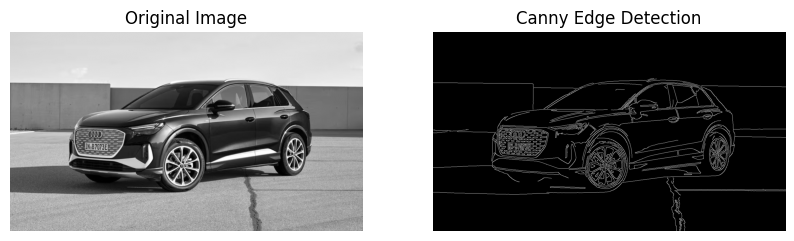

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load the image
image_path = "/content/rgb_car.jpg"  # Replace with the path to your image
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)  # Load as grayscale

# Apply Gaussian blur to reduce noise (optional step before Canny)
blurred_image = cv2.GaussianBlur(image, (5, 5), 1.4)

# Apply Canny edge detection
lower_threshold = 50  # Lower threshold for edge detection
upper_threshold = 150  # Upper threshold for edge detection
edges = cv2.Canny(blurred_image, lower_threshold, upper_threshold)

# Display the original and edge-detected images
plt.figure(figsize=(10, 5))

# Original image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(image, cmap='gray')
plt.axis('off')

# Edge-detected image
plt.subplot(1, 2, 2)
plt.title("Canny Edge Detection")
plt.imshow(edges, cmap='gray')
plt.axis('off')

plt.show()


**Questions:**
1. What do the horizontal and vertical gradients represent in the context of
edge detection?\
They represent the rate of intensity change along the x-axis and y-axis, respectively. These gradients help in identifying potential edges by highlighting where significant changes occur in the image.
2.   What do the gradient magnitude and direction represent in the context of
edge detection?\
The gradient magnitude measures the strength of an edge by quantifying the overall rate of change in intensity. In contrast, the gradient direction indicates the orientation of the edge, showing the angle at which the intensity change is maximized.
3.   How does non-maximum suppression help in refining the edges?\
This technique refines edge detection by preserving only the local maxima in the gradient magnitude along the gradient direction. It thins the edges to a single pixel width, eliminating spurious responses and ensuring that only the most relevant edge pixels are retained.
4.   How does double thresholding help in distinguishing between strong and
weak edges?\
Double thresholding distinguishes between strong and weak edges by applying two different threshold values. Strong edges, which exceed the higher threshold, are considered reliable, while weak edges falling between the thresholds are marked for potential inclusion, reducing the likelihood of noise being mistaken for an edge.
5.   How does hysteresis thresholding help in connecting edges?\
Hysteresis thresholding connects edges by linking weak edge pixels to strong ones if they are adjacent. This step helps to form continuous edges by validating weak pixels as part of an edge only when they are connected to confirmed strong edges.





> **Problem 10:Gaussian Pyramid**



In [ ]:
import numpy as np
from scipy.ndimage import gaussian_filter

# Input Image
I = np.array([
    [10, 20, 30, 40],
    [50, 60, 70, 80],
    [90, 100, 110, 120],
    [130, 140, 150, 160]
], dtype=np.float64)

# Function to create Gaussian pyramid
def gaussian_pyramid(image, levels=3, sigma=1):
    pyramid = [image]  # The first level is the original image
    for i in range(1, levels):
        # Step 1: Blur the image using a Gaussian filter
        blurred = gaussian_filter(pyramid[i-1], sigma=sigma)
        # Step 2: Subsample the image by taking every second row and column
        subsampled = blurred[::2, ::2]
        pyramid.append(subsampled)
    return pyramid

# Create Gaussian pyramid
pyramid = gaussian_pyramid(I, levels=3, sigma=1)

# Print the pyramid
for i, level in enumerate(pyramid):
    print(f"Level {i}:\n{level}\n")


Level 0:
[[ 10.  20.  30.  40.]
 [ 50.  60.  70.  80.]
 [ 90. 100. 110. 120.]
 [130. 140. 150. 160.]]

Level 1:
[[ 31.34535599  46.44505967]
 [ 91.74417072 106.8438744 ]]

Level 2:
[[58.10094088]]



Level 0 shape: (727, 1287)
Level 1 shape: (364, 644)
Level 2 shape: (182, 322)
Level 3 shape: (91, 161)


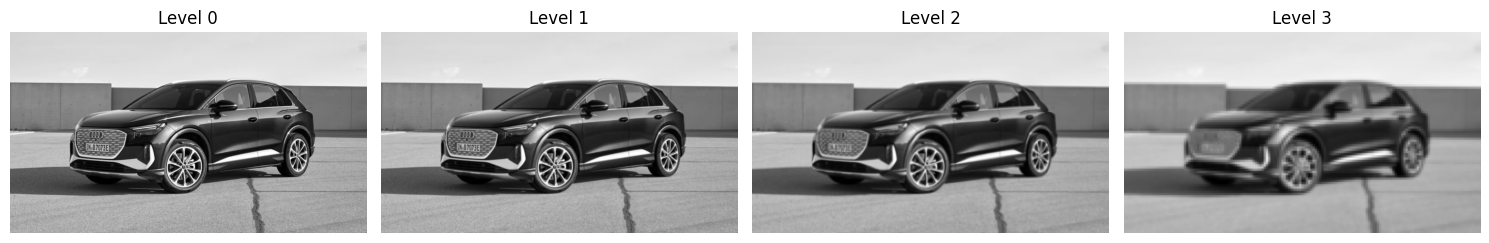

In [ ]:
import cv2
import matplotlib.pyplot as plt

# Load the image
image_path = "/content/rgb_car.jpg"  # Replace with the path to your image
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)  # Load as grayscale

# Number of pyramid levels
num_levels = 4

# Create the Gaussian Pyramid
gaussian_pyramid = [image]  # The first level is the original image
for i in range(1, num_levels):
    downsampled_image = cv2.pyrDown(gaussian_pyramid[i - 1])  # Downsample the previous level
    gaussian_pyramid.append(downsampled_image)

# Print the shape of each level
for i, level in enumerate(gaussian_pyramid):
    print(f"Level {i} shape: {level.shape}")

# Display the Gaussian Pyramid
plt.figure(figsize=(15, 8))
for i, level in enumerate(gaussian_pyramid):
    plt.subplot(1, num_levels, i + 1)
    plt.title(f"Level {i}")
    plt.imshow(level, cmap='gray')
    plt.axis('off')

plt.tight_layout()
plt.show()


**Questions:**

1. How does the Gaussian pyramid help in multi-scale image analysis?\
The Gaussian pyramid is a multi-scale representation that progressively reduces image resolution through smoothing and downsampling. This approach enables the capture of both fine details and larger structures across different scales. By analyzing images at multiple resolutions, it improves computational efficiency and helps achieve scale invariance in feature detection. Ultimately, this enhances the robustness of image analysis, allowing for more reliable object recognition regardless of size variations.

# **HARRIS CORNER DETECTION**



>  **Problem 11: Corner Response**



In [ ]:
import numpy as np

# Define the matrix M
M = np.array([
    [30, 24],
    [24, 39]
])

# Define the constant k
k = 0.04

# Compute determinant and trace of M
det_M = np.linalg.det(M)
trace_M = np.trace(M)

# Compute corner response R using Harris formula
R = det_M - k * (trace_M ** 2)

# Print results
print("Determinant of M:", det_M)
print("Trace of M:", trace_M)
print("Corner Response R:", R)


Determinant of M: 594.0000000000001
Trace of M: 69
Corner Response R: 403.5600000000001




>  **Problem 12: Eigenvalue Analysis**



In [ ]:
import numpy as np

# Define the matrix M
M = np.array([
    [30, 24],
    [24, 39]
])

# Compute eigenvalues and eigenvectors using NumPy's eig function
eigenvalues, eigenvectors = np.linalg.eig(M)

# Print the results
print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors:")
print(eigenvectors)


Eigenvalues:
[10.08176911 58.91823089]

Eigenvectors:
[[-0.76950911 -0.63863584]
 [ 0.63863584 -0.76950911]]


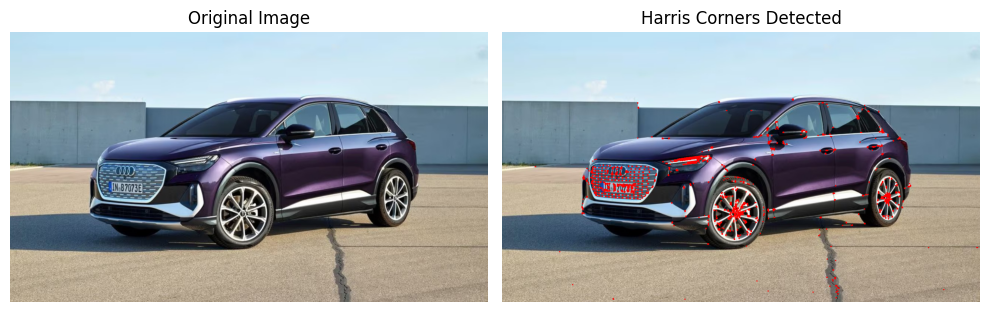

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the image
image_path = "/content/rgb_car.jpg"  # Replace with the path to your image
image = cv2.imread(image_path)  # Load the image in BGR format

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Convert to float32 (required for Harris corner detection)
gray = np.float32(gray)

# Apply Harris Corner Detection
block_size = 2  # Size of neighborhood considered for corner detection
ksize = 3       # Aperture parameter for Sobel operator
k = 0.04        # Harris detector free parameter
dst = cv2.cornerHarris(gray, block_size, ksize, k)

# Dilate the result to mark the corners more clearly
dst = cv2.dilate(dst, None)

# Threshold for an optimal value and mark corners in red
threshold = 0.01 * dst.max()
corner_image = image.copy()  # Create a copy of the original image
corner_image[dst > threshold] = [0, 0, 255]  # Mark corners in red on the copy

# Display the original and corner-detected images
plt.figure(figsize=(10, 5))

# Original image
plt.subplot(1, 2, 1)
plt.title("Original Image")
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis('off')

# Image with detected corners
plt.subplot(1, 2, 2)
plt.title("Harris Corners Detected")
plt.imshow(cv2.cvtColor(corner_image, cv2.COLOR_BGR2RGB))
plt.axis('off')

plt.tight_layout()
plt.show()


**Questions:**

1.   What does a positive corner response indicate about a point in the image?\
A positive corner response indicates that a point in the image has significant intensity variation in multiple directions, suggesting that the point is likely a well-defined corner. This response is typically derived from a combination of eigenvalues of the local autocorrelation matrix, which quantify the strength of directional changes.
2.   How do the eigenvalues help in distinguishing between corners, edges, and
flat regions?\
The eigenvalues of the local structure matrix help distinguish image regions by quantifying intensity variation along different directions. When both eigenvalues are large, the point is likely a corner; if one is large and the other is small, the point lies on an edge; and if both are small, the region is flat, exhibiting minimal variation.

# **SIFT Feature Descriptor**

1.   Problem 13: Difference of Gaussians (DoG)
2.   Problem 14: Orientation Assignment



In [ ]:
import numpy as np
from scipy.ndimage import gaussian_filter

# Example image patch
image_patch = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
], dtype=np.float64)

# Define scales
sigma = 1.6
k_sigma = 1.92

# Apply Gaussian blur with sigma
blurred_sigma = gaussian_filter(image_patch, sigma=sigma)

# Apply Gaussian blur with k_sigma
blurred_k_sigma = gaussian_filter(image_patch, sigma=k_sigma)

# Compute Difference of Gaussians (DoG)
DoG = blurred_sigma - blurred_k_sigma

# Print results
print("Blurred Image (σ=1.6):\n", blurred_sigma)
print("\nBlurred Image (kσ=1.92):\n", blurred_k_sigma)
print("\nDifference of Gaussians (DoG):\n", DoG)


Blurred Image (σ=1.6):
 [[40.17262012 42.62946509 45.08631006]
 [47.54315503 50.         52.45684497]
 [54.91368994 57.37053491 59.82737988]]

Blurred Image (kσ=1.92):
 [[44.70031664 46.02523748 47.35015832]
 [48.67507916 50.         51.32492084]
 [52.64984168 53.97476252 55.29968336]]

Difference of Gaussians (DoG):
 [[-4.52769652 -3.39577239 -2.26384826]
 [-1.13192413  0.          1.13192413]
 [ 2.26384826  3.39577239  4.52769652]]


In [ ]:
import numpy as np
from scipy.ndimage import sobel

# Example image patch
image_patch = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
], dtype=np.float64)

# Compute horizontal and vertical gradients using Sobel filters
Gx = sobel(image_patch, axis=1)  # Gradient in x-direction
Gy = sobel(image_patch, axis=0)  # Gradient in y-direction

# Compute gradient magnitude and orientation
gradient_magnitude = np.sqrt(Gx**2 + Gy**2)
gradient_orientation = np.arctan2(Gy, Gx) * (180 / np.pi)  # Convert to degrees

# Create histogram of orientations (binning into angles from -180° to +180°)
histogram_bins = np.histogram(gradient_orientation, bins=8, range=(-180, 180))

# Print results
print("Gradient Magnitude:\n", gradient_magnitude)
print("\nGradient Orientation (degrees):\n", gradient_orientation)
print("\nHistogram of Orientations:\n", histogram_bins[0])

Gradient Magnitude:
 [[126.49110641 144.22205102 126.49110641]
 [243.31050121 252.98221281 243.31050121]
 [126.49110641 144.22205102 126.49110641]]

Gradient Orientation (degrees):
 [[71.56505118 56.30993247 71.56505118]
 [80.53767779 71.56505118 80.53767779]
 [71.56505118 56.30993247 71.56505118]]

Histogram of Orientations:
 [0 0 0 0 0 9 0 0]


**Questions:**

1.    Why is the DoG used in SIFT for scale-space extrema detection?\
The Difference of Gaussian (DoG) is used in SIFT for scale-space extrema detection because it efficiently approximates the Laplacian of Gaussian, which is ideal for identifying regions of rapid intensity change. By subtracting Gaussian-blurred images at different scales, the DoG highlights key features that remain stable across scales. This approach reduces computational complexity while maintaining robust detection of keypoints in the image.
2.   How does the orientation assignment make SIFT features invariant to
rotation?\
The orientation assignment in SIFT makes features invariant to rotation by aligning the descriptor with the dominant gradient orientation within the keypoint’s neighborhood. By computing a histogram of gradient directions, the algorithm assigns a consistent orientation to each keypoint. This normalization ensures that the feature descriptor remains consistent regardless of how the image is rotated, thereby enhancing matching accuracy across different views.



> **HOUGH TRANSFORM**

*   Problem 15: Line Detection
*   Problem 16: Circle Detection




In [ ]:
# LIne Detection
import numpy as np

# Edge points
points = [(1, 1), (2, 2), (3, 3)]

# Angle in degrees and convert to radians
theta = 45  # in degrees
theta_rad = np.deg2rad(theta)  # convert to radians

# Compute cos(theta) and sin(theta)
cos_theta = np.cos(theta_rad)
sin_theta = np.sin(theta_rad)

# Compute rho for each point
rho_values = [x * cos_theta + y * sin_theta for x, y in points]

# Print results
print("Line Detection")
for point, rho in zip(points, rho_values):
    print(f"Point {point}: ρ = {rho:.4f}")

Line Detection
Point (1, 1): ρ = 1.4142
Point (2, 2): ρ = 2.8284
Point (3, 3): ρ = 4.2426


In [ ]:
# Circle Detection
import numpy as np

# Edge point and radius
edge_point = (2, 2)
r = 2

# Generate possible center points (a, b) on a circle of radius r around the edge point
# We'll sample points on the circle using polar coordinates
angles = np.linspace(0, 2 * np.pi, 8)  # Sample 8 points around the circle
a_values = edge_point[0] + r * np.cos(angles)
b_values = edge_point[1] + r * np.sin(angles)

# Print results
print("Circle Detection")
for a, b in zip(a_values, b_values):
    print(f"Possible center: (a, b) = ({a:.4f}, {b:.4f})")


Circle Detection
Possible center: (a, b) = (4.0000, 2.0000)
Possible center: (a, b) = (3.2470, 3.5637)
Possible center: (a, b) = (1.5550, 3.9499)
Possible center: (a, b) = (0.1981, 2.8678)
Possible center: (a, b) = (0.1981, 1.1322)
Possible center: (a, b) = (1.5550, 0.0501)
Possible center: (a, b) = (3.2470, 0.4363)
Possible center: (a, b) = (4.0000, 2.0000)


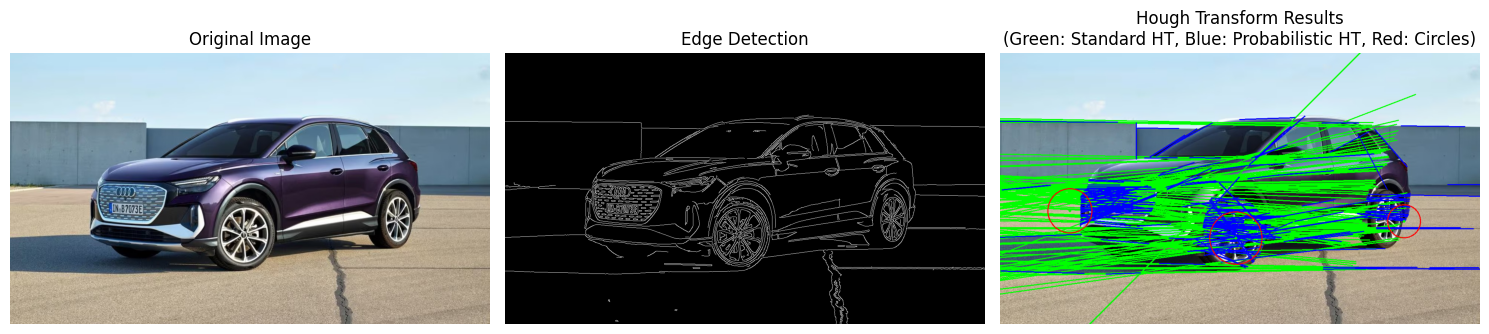

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def hough_transform(image_path):
    # Load image
    img = cv2.imread(image_path)
    original = img.copy()
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Apply Gaussian blur and edge detection
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    edges = cv2.Canny(blurred, 50, 150)

    # Line Detection

    # Standard Hough Transform (returns polar coordinates)
    lines = cv2.HoughLines(edges, 1, np.pi/180, threshold=150)

    # Draw lines (polar coordinates)
    if lines is not None:
        for line in lines:
            rho, theta = line[0]
            a = np.cos(theta)
            b = np.sin(theta)
            x0 = a * rho
            y0 = b * rho
            pt1 = (int(x0 + 1000*(-b)), int(y0 + 1000*(a)))
            pt2 = (int(x0 - 1000*(-b)), int(y0 - 1000*(a)))
            cv2.line(img, pt1, pt2, (0, 255, 0), 2)

    # Probabilistic Hough Transform (returns line segments)
    linesP = cv2.HoughLinesP(edges, 1, np.pi/180, threshold=80,
                            minLineLength=80, maxLineGap=20)

    # Draw line segments
    if linesP is not None:
        for line in linesP:
            x1, y1, x2, y2 = line[0]
            cv2.line(img, (x1, y1), (x2, y2), (255, 0, 0), 2)


    # Circle Detection

    # Detect circles using Hough transform
    circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, dp=1.2,
                              minDist=450,
                              param1=180, param2=30,
                              minRadius=20, maxRadius=80)

    # Draw detected circles
    if circles is not None:
        circles = np.uint16(np.around(circles))
        for i in circles[0,:]:
            # Draw outer circle
            cv2.circle(img, (i[0], i[1]), i[2], (0, 0, 255), 2)
            # Draw center
            cv2.circle(img, (i[0], i[1]), 2, (0, 255, 0), 3)

    # Display results
    plt.figure(figsize=(15, 8))

    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(cv2.cvtColor(original, cv2.COLOR_BGR2RGB))
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title("Edge Detection")
    plt.imshow(edges, cmap='gray')
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title("Hough Transform Results\n(Green: Standard HT, Blue: Probabilistic HT, Red: Circles)")
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Usage example
hough_transform("/content/rgb_car.jpg")


**Questions:**

1.   How does the Hough Transform detect lines in an image?\
The Hough Transform detects lines by mapping edge points from the image into a parameter space defined by line equations (typically using parameters ρ and θ). Each edge point votes for all potential lines that could pass through it, and peaks in this accumulator space indicate the presence of a line with specific parameters. This voting process effectively aggregates evidence from multiple points to robustly identify lines even in the presence of noise.
2.   Why is the Hough Transform useful for detecting circles and other shapes?\
The Hough Transform can be generalized to detect circles and other parametric shapes by adapting the parameter space to the specific geometric model. For instance, circles can be described by parameters for the center coordinates and radius. By accumulating votes in this higher-dimensional space, the transform can identify shapes even when parts of the shape are missing or occluded. This flexibility makes the Hough Transform a powerful tool for recognizing various shapes in complex images.



>**RANSAC**

1.   Problem 17: RANSAC Iterations
2.   Problem 18: Model Fitting





Inliers (X, y):
[[ 1]
 [ 2]
 [ 3]
 [10]] [ 2  3  4 10]

Outliers (X, y):
[] []

Fitted model coefficients (slope, intercept):
[0.88] 1.2299999999999982


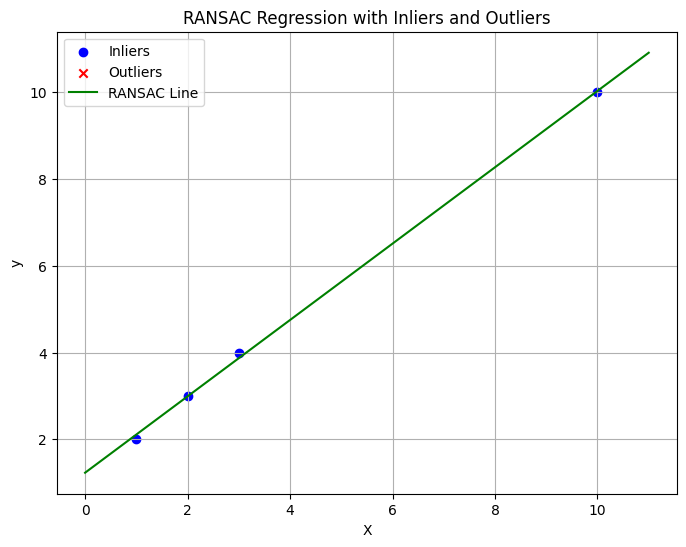

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import RANSACRegressor, LinearRegression

# Data points
X = np.array([[1], [2], [3], [10]])  # Feature values
y = np.array([2, 3, 4, 10])         # Target values

# Initialize RANSAC model with Linear Regression as the estimator
ransac = RANSACRegressor(estimator=LinearRegression(), residual_threshold=1)

# Fit the model to the data
ransac.fit(X, y)

# Identify inliers and outliers
inlier_mask = ransac.inlier_mask_  # Boolean mask for inliers
outlier_mask = ~inlier_mask        # Boolean mask for outliers

# Extract inliers and outliers
inliers_X = X[inlier_mask]
inliers_y = y[inlier_mask]
outliers_X = X[outlier_mask]
outliers_y = y[outlier_mask]

# Print results
print("Inliers (X, y):")
print(inliers_X, inliers_y)
print("\nOutliers (X, y):")
print(outliers_X, outliers_y)

# Print the fitted model coefficients
print("\nFitted model coefficients (slope, intercept):")
print(ransac.estimator_.coef_, ransac.estimator_.intercept_)

# Plotting the RANSAC Results

# Generate points for the fitted line
x_plot = np.linspace(0, 11, 100).reshape(-1, 1) # Range slightly beyond data points
y_plot = ransac.predict(x_plot)

# Plot the data
plt.figure(figsize=(8, 6))

# Plot inliers
plt.scatter(inliers_X, inliers_y, color='blue', marker='o', label='Inliers')

# Plot outliers
plt.scatter(outliers_X, outliers_y, color='red', marker='x', label='Outliers')

# Plot the fitted line
plt.plot(x_plot, y_plot, color='green', linestyle='-', label='RANSAC Line')

# Customize the plot
plt.xlabel('X')
plt.ylabel('y')
plt.title('RANSAC Regression with Inliers and Outliers')
plt.legend(loc='upper left')
plt.grid(True)

# Show the plot
plt.show()


**Questions:**

1.   How does RANSAC handle outliers in data?\
RANSAC tackles outliers by randomly selecting a minimal subset of data points to estimate a model and then determining which points fit this model within a set tolerance. This process identifies inliers (points that conform to the model) and excludes outliers. The algorithm iterates this procedure, ultimately choosing the model that has the highest consensus among inliers.
2.   Why is RANSAC preferred for robust model fitting in noisy data?\
RANSAC is favored for noisy data because it is resilient to a large proportion of outliers. Unlike traditional fitting methods that can be significantly skewed by anomalous points, RANSAC’s iterative approach focuses on the consensus set, ensuring that the final model is representative of the underlying data structure. This robustness makes it highly effective for real-world applications where noise is prevalent.
